# Hands-On — Data, Monte Carlo, and Detector Response Using Public IceCube Data

**PhD school · Analysis Techniques in Neutrino Astronomy**  
**STUDENT NOTEBOOK — exercises to complete**

### Why HESE?

We use the HESE sample for this hands-on because IceCube has made both the observed events and a selected sample of simulated Monte Carlo events **publicly available**, together with useful information about event properties, simulation weights, and neutrino interactions. This makes it a convenient dataset for exploring, in practice, several concepts discussed in the lecture *Analysis Techniques in Neutrino Astronomy*: **MC reweighting, atmospheric backgrounds, astrophysical neutrino fluxes, event selections, and detector response.**

### Learning goals
Explore observed and simulated events; turn a neutrino flux into expected counts; investigate astrophysical and atmospheric components; derive the HESE effective area; and discuss what can be learned about reconstructed energy and direction.

### Suggested route for a 90-minute hands-on

| Activity | Suggested time | Priority |
|---|---:|---|
| Set up the HESE data | 10 min | Essential |
| Exercise 1 — weights and event counts | 15 min | Essential |
| Exercise 2 — observed data vs MC | 20 min | Essential |
| Exercise 3 — spectral-index dependence | 15 min | Essential |
| Exercise 4 — atmospheric fluxes and veto | 15 min | Essential |
| Exercise 5 — effective area | 15 min | Essential |
| Additional selections, Exercises 6–7 | After session / if time remains | Optional |

The exercises build on one another. **First complete `astro_counts()` in Exercise 1**, since later exercises use it. The utility functions for downloading data, plotting, atmospheric backgrounds and weighted quantiles are already provided.

**Official resources:** [HESE data release](https://icecube.wisc.edu/data-releases/2021/12/hese-7-5-year-data/) · [Variable dictionary and code](https://github.com/icecube/HESE-7-year-data-release) · [IceCube HESE paper](https://arxiv.org/pdf/2011.03545).

> The release contains 102 observed HESE events and a *selected* MC sample. The MC provides truth information and weights that are not present in the observed data. Instructor solutions will be published after the hands-on session.


In [1]:
# The following libraries are needed to load and process the
# IceCube HESE public dataset, perform numerical calculations,
# and visualize the results.
#
# - json, pathlib, urllib, zipfile, shutil:
#   Handle files, directories, and dataset downloads.
#   These modules are included in the Python standard library.
#
# - numpy:
#   Numerical calculations, arrays, and histogram binning.
#
# - pandas:
#   Load, organize, and explore the data and MC samples.
#
# - matplotlib:
#   Create plots and visualize data/MC comparisons.
#
# Make sure you have installed the required packages following
# the instructions in the repository README.md.

import json
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# Set default plotting style
plt.rcParams.update({
    'figure.figsize': (8, 4.8),
    'axes.grid': True,
    'grid.alpha': 0.22
})

## A. Set up the official data release

Run the following cells. The notebook first searches for locally extracted `HESE_*.json` files, then downloads the 75-MB official ZIP if needed. If internet is unavailable, download the ZIP from the [official release](https://icecube.wisc.edu/data-releases/2021/12/hese-7-5-year-data/) and put it beside this notebook.

**Units/meanings to inspect in the README:**

| Field | Meaning / units |
|---|---|
| `primaryEnergy`, `primaryZenith`, `primaryType`, `interactionType` | MC truth: GeV, rad, PDG code, interaction category |
| `recoDepositedEnergy`, `recoZenith`, `recoMorphology`, `recoLength` | Data and MC reconstructed: GeV, rad, 0=cascade/1=track/2=double cascade, m |
| `weightOverFluxOverLivetime` | neutrino normalization factor; **GeV sr cm²** (zero for muons) |
| `pionFlux`, `kaonFlux`, `promptFlux` | atmospheric differential flux per MC event; **GeV⁻¹ s⁻¹ sr⁻¹ cm⁻²** |
| `conventionalSelfVetoCorrection`, `promptSelfVetoCorrection` | dimensionless veto passing fractions |
| `muonWeightOverLivetime` | atmospheric muon expected rate contribution (**s⁻¹**), zero for neutrinos |

**Caution about flux conventions:** `PHI0` below is an **illustrative differential flux for each particle species represented by a positive neutrino MC entry**, not the published all-flavor HESE best-fit normalization.

### Particle identification: PDG codes

In the Monte Carlo sample, the variable `primaryType` identifies the simulated primary particle using the **Particle Data Group (PDG) code**.

Official documentation:  
https://pdg.lbl.gov/2025/reviews/rpp2025-rev-monte-carlo-numbering.pdf


| Particle | PDG code |
|---|---:|
| Electron neutrino ($\nu_e$) | `12` |
| Electron antineutrino ($\bar{\nu}_e$) | `-12` |
| Muon neutrino ($\nu_\mu$) | `14` |
| Muon antineutrino ($\bar{\nu}_\mu$) | `-14` |
| Tau neutrino ($\nu_\tau$) | `16` |
| Tau antineutrino ($\bar{\nu}_\tau$) | `-16` |
| Muon ($\mu^-$) | `13` |
| Antimuon ($\mu^+$) | `-13` |

**Note:** Neutrinos have positive PDG codes, while antineutrinos have negative codes.

To select a neutrino flavour including both neutrinos and antineutrinos, use the absolute value of `primaryType`.

For example, to select all muon neutrinos and antineutrinos:

```python
mask = np.abs(df_mc["primaryType"]) == 14
```

### Interaction categories in the HESE MC

The `interactionType` variable distinguishes the simulated neutrino interaction channel:

| `interactionType` | Meaning |
|---:|---|
| `0` | Simulated atmospheric muon (not a neutrino interaction) |
| `1` | Charged-current neutrino interaction (CC) |
| `2` | Neutral-current neutrino interaction (NC) |
| `3` | Glashow-resonance interaction (GR) |

Reference: [IceCube HESE release — variable descriptions](https://github.com/icecube/HESE-7-year-data-release).


In [2]:
FILES = ('HESE_data.json', 'HESE_mc_truth.json', 'HESE_mc_observable.json', 'HESE_mc_flux.json')
DATA_DIR = Path('HESE_7p5_data')
ARCHIVE_PATH = Path('20211217_HESE-7-5-year-data.zip')
ARCHIVE_URL = 'https://icecube.wisc.edu/data-releases/20211217_HESE-7-5-year-data.zip'

LIVETIME_S = 227708167.68  # Historical HESE observation livetime [s]
E0_GEV = 1e5               # Astrophysical flux pivot: 100 TeV
PHI0 = 1e-18               # Illustrative PER-PARTICLE-SPECIES normalization
                           # [GeV^-1 cm^-2 s^-1 sr^-1]

# OPTIONAL (after the core exercises):
# Find the published best-fit gamma and flux normalization in
# https://arxiv.org/pdf/2011.03545
# Check the energy pivot and whether the quoted normalization is all-flavor
# or per particle species; convert before using it in astro_flux().


In [3]:
def prepare_release(target=DATA_DIR):
    """Prefer local files; otherwise download/extract the four official JSON files."""
    target.mkdir(exist_ok=True)
    if all((target / f).is_file() for f in FILES):
        print('Using existing HESE files:', target.resolve())
        return target
    for base in (Path('resources/data'),
                 Path('HESE-7-year-data-release/resources/data'),
                 Path('HESE-7-year-data-release/HESE-7-year-data-release/resources/data')):
        if all((base / f).is_file() for f in FILES):
            print('Using existing extracted release:', base.resolve())
            return base
    if not ARCHIVE_PATH.is_file():
        try:
            print('Downloading the 75-MB official IceCube ZIP (once).')
            urlretrieve(ARCHIVE_URL, ARCHIVE_PATH)
        except Exception as exc:
            raise RuntimeError('Automatic download unavailable. Download the ZIP manually from '
                               'https://icecube.wisc.edu/data-releases/2021/12/hese-7-5-year-data/ '
                               'and save it beside this notebook as '+str(ARCHIVE_PATH)) from exc
    with ZipFile(ARCHIVE_PATH) as z:
        for f in FILES:
            matches = [name for name in z.namelist() if name.endswith('/resources/data/'+f)
                       or name == 'resources/data/'+f]
            if len(matches) != 1:
                raise ValueError(f'Expected one {f} in the archive, found {len(matches)}')
            with z.open(matches[0]) as source, (target/f).open('wb') as dest:
                shutil.copyfileobj(source, dest)
    print('Extracted files to', target.resolve())
    return target

def load_json(path):
    with path.open(encoding='utf-8') as f:
        return {k: np.asarray(v) for k, v in json.load(f).items()}

data_dir = prepare_release()
df_data = pd.DataFrame(load_json(data_dir / 'HESE_data.json'))
mc_columns = {}
for filename in FILES[1:]:
    record = load_json(data_dir/filename)
    overlap = set(mc_columns).intersection(record)
    if overlap:
        raise ValueError(f'Overlapping MC column names in {filename}: {overlap}')
    mc_columns.update(record)
df_mc = pd.DataFrame(mc_columns)
assert len(df_data) == 102, 'Unexpected number of observed HESE events: check the release.'
assert len(df_mc) > 0
print(f'{len(df_data)} observed events; {len(df_mc):,} selected MC entries')
print('Data columns:', df_data.columns.tolist())
print('MC columns:', df_mc.columns.tolist())

Using existing HESE files: /Users/angela/Desktop/Meeting&Conferences/PhDSchool_ACME/neutrino_astronomy_hands_on/GitHub/HESE_7p5_data
102 observed events; 821,764 selected MC entries
Data columns: ['recoDepositedEnergy', 'recoMorphology', 'recoZenith', 'recoLength']
MC columns: ['primaryType', 'primaryZenith', 'primaryEnergy', 'weightOverFluxOverLivetime', 'interactionType', 'recoDepositedEnergy', 'recoLength', 'recoZenith', 'recoMorphology', 'pionFlux', 'kaonFlux', 'promptFlux', 'conventionalSelfVetoCorrection', 'promptSelfVetoCorrection', 'muonWeightOverLivetime']


## B. From generation weight to event rate

The released `weightOverFluxOverLivetime` contains the relevant MC normalization. **Data** have one count per event; **MC** have model-dependent counts after multiplying by livetime. The notebook uses `T = 227708167.68 s` from the historical analysis (livetime in the HESE paper).

Atmospheric muons have a separately supplied `muonWeightOverLivetime`; multiplying them by a neutrino flux would be incorrect.

### Exercise 1 — From flux to expected events

In the previous lecture, we discussed how Monte Carlo events can be reweighted to represent different physical flux hypotheses.

**Your task:**

1. Implement the function `astro_counts()` to calculate the expected contribution of each MC event for a given astrophysical flux.
2. Inspect the units of `weightOverFluxOverLivetime`. What are the units of the resulting weights after multiplying by the flux?
3. How do you obtain the expected number of detected events during the observation period?
4. Calculate the expected number of events for spectral indices $\gamma = 2.0,\ 2.7,\ 3.8$.
5. Which spectral index predicts the largest number of events? Does this depend on the reference energy and flux normalization?

**Hint:** Recall the relationship between generation weights, physical flux, and observation time discussed in the lecture.

In [4]:
# Common arrays used throughout the exercises
E_true = df_mc['primaryEnergy'].to_numpy(dtype=float)
w0 = df_mc['weightOverFluxOverLivetime'].to_numpy(dtype=float)
T = LIVETIME_S
is_neutrino = (w0 > 0) & np.isfinite(E_true) & (E_true > 0)

def astro_flux(energy_gev, gamma, phi0=None):
    """Astrophysical differential flux per particle species [GeV^-1 cm^-2 s^-1 sr^-1]."""
    if phi0 is None:
        phi0 = PHI0
    energy_gev = np.asarray(energy_gev, dtype=float)
    return phi0 * (energy_gev / E0_GEV)**(-gamma)

def astro_counts(gamma, phi0=None):
    """Expected number of events contributed by each selected neutrino MC entry."""
    # Start from zero for non-neutrino or invalid entries.
    counts = np.zeros(len(df_mc), dtype=float)
    mask = is_neutrino & np.isfinite(w0)

    # Calculate the assumed physical flux at the TRUE neutrino energy.
    flux = astro_flux(E_true[mask], gamma, phi0)

    # w0 * flux has units s^-1; multiplication by T gives expected counts.
    counts[mask] = T * w0[mask] * flux
    return counts


In the cell below, a function for the atmospheric background is provided.

The `background_counts()` function calculates the expected number of background events in the HESE sample, considering three main contributions: **conventional atmospheric neutrinos, prompt atmospheric neutrinos, and atmospheric muons**.

These components originate from different physical processes in cosmic-ray air showers and are therefore modeled and weighted differently in the Monte Carlo simulation.

Before exploring the function, it is important to understand the physical origin of each background component, the meaning of the corresponding fluxes and weights, and the role of the atmospheric neutrino self-veto in the HESE event selection.

### Atmospheric background components

In addition to astrophysical neutrinos, the HESE sample contains background events originating from cosmic-ray interactions in the Earth's atmosphere.

We consider three main background contributions:

#### 1. Conventional atmospheric neutrinos

When cosmic rays interact with atmospheric nuclei, they produce secondary particles, including charged pions ($\pi^\pm$) and kaons ($K^\pm$).

These particles can decay and produce neutrinos, mainly electron and muon neutrinos.

The conventional atmospheric neutrino flux is the sum of the contributions from pion and kaon decays:

$$
\Phi_{\mathrm{conv}}(E_\nu,\Omega)
=
\Phi_\pi(E_\nu,\Omega)
+
\Phi_K(E_\nu,\Omega).
$$

In the HESE Monte Carlo sample, these contributions are provided by:

- `pionFlux`: atmospheric neutrino flux from pion decays.
- `kaonFlux`: atmospheric neutrino flux from kaon decays.

At high energies, conventional atmospheric neutrino spectra are steeper than the primary cosmic-ray spectrum. This happens because high-energy pions and kaons are increasingly likely to interact in the atmosphere before decaying.

#### 2. Prompt atmospheric neutrinos

Prompt atmospheric neutrinos originate mainly from the decay of short-lived hadrons containing charm quarks, produced in cosmic-ray interactions.

Unlike pions and kaons, charmed hadrons decay very rapidly, typically before interacting again.

As a result, the prompt neutrino spectrum is harder than the conventional atmospheric neutrino spectrum and follows the primary cosmic-ray spectrum more closely.

In the HESE sample, the nominal prompt flux is provided by `promptFlux`.

**Question:** Why can the prompt component become increasingly important relative to the conventional component at high energies?

#### 3. Atmospheric muons

Cosmic-ray air showers also produce large numbers of muons.

Some atmospheric muons can penetrate deep into the ice and reach IceCube. If they are not rejected by the detector veto, they can mimic neutrino-induced events.

Unlike conventional and prompt atmospheric neutrinos, atmospheric muons are simulated using a separate MC sample.

Their event rates are provided by `muonWeightOverLivetime` **[s⁻¹]**, which already includes the nominal muon simulation normalization, divided by the detector livetime.

Therefore, no additional neutrino flux multiplication is required for atmospheric muons.

#### 4. Atmospheric neutrino self-veto (see slide 13)

Atmospheric neutrinos and muons can be produced in the **same cosmic-ray air shower**.

For downgoing atmospheric neutrinos, accompanying muons may reach IceCube and trigger the veto, causing the neutrino event to be rejected.

This effect is called the **atmospheric neutrino self-veto**.

The HESE release provides two passing fractions:

- `conventionalSelfVetoCorrection`: probability that a conventional atmospheric neutrino passes the self-veto.
- `promptSelfVetoCorrection`: probability that a prompt atmospheric neutrino passes the self-veto.

These corrections depend on the properties of the event, including energy, direction, and neutrino type.

The corrected flux contributions are:

$$
\Phi_{\mathrm{conv}}^{\mathrm{eff}}
=
(\Phi_\pi+\Phi_K)\,P_{\mathrm{passing}}^{\mathrm{conv}}
$$

$$
\Phi_{\mathrm{prompt}}^{\mathrm{eff}}
=
\Phi_{\mathrm{prompt}}\,P_{\mathrm{passing}}^{\mathrm{prompt}}.
$$

Here, $P_{\mathrm{passing}}$ is a probability between 0 and 1.

**Important:** The atmospheric neutrino self-veto correction is not applied to the astrophysical flux. Astrophysical neutrinos are not produced in cosmic-ray air showers in the Earth's atmosphere.

#### 5. From atmospheric fluxes to expected event counts

As for the astrophysical component, we multiply the atmospheric neutrino fluxes by the MC normalization weights and the observation livetime:

$$
N_{i,\mathrm{conv}}
=
T\,w_{0,i}\,
(\Phi_{\pi,i}+\Phi_{K,i})\,
P_{\mathrm{passing},i}^{\mathrm{conv}}
$$

$$
N_{i,\mathrm{prompt}}
=
T\,w_{0,i}\,
\Phi_{\mathrm{prompt},i}\,
P_{\mathrm{passing},i}^{\mathrm{prompt}}
$$

For atmospheric muons, instead:

$$
N_{i,\mu}
=
T\,w_{\mu,i}
$$

where $w_{\mu,i}$ is the value of `muonWeightOverLivetime`.

The parameters `conv_scale`, `prompt_scale`, and `muon_scale` allow us to modify the normalization of each background component independently.

The total predicted number of events is then:

$$
N_{\mathrm{total}}
=
N_{\mathrm{astro}}
+
N_{\mathrm{conv}}
+
N_{\mathrm{prompt}}
+
N_{\mu}.
$$

In [5]:
def background_counts(conv_scale=1., prompt_scale=1., muon_scale=1., self_veto=True):
    """Event counts from nominal atm neutrino fluxes and muon MC."""
    d = df_mc
    conv_flux = (d['pionFlux'].to_numpy(float) + d['kaonFlux'].to_numpy(float))
    prompt_flux = d['promptFlux'].to_numpy(float)
    if self_veto:
        conv_flux = conv_flux * d['conventionalSelfVetoCorrection'].to_numpy(float)
        prompt_flux = prompt_flux * d['promptSelfVetoCorrection'].to_numpy(float)
    conv = np.where(is_neutrino,
                    np.nan_to_num(T * w0 * conv_flux * conv_scale, nan=0., posinf=0., neginf=0.),
                    0.)
    prompt = np.where(is_neutrino,
                      np.nan_to_num(T * w0 * prompt_flux * prompt_scale, nan=0., posinf=0., neginf=0.),
                      0.)
    muon = np.nan_to_num(T * d['muonWeightOverLivetime'].to_numpy(float) * muon_scale)
    return {'Conventional atm. ν': conv, 'Prompt atm. ν': prompt, 'Atm. μ': muon}



### Helper functions: Data/MC comparison and weighted quantiles

Before starting the exercises, we define two helper functions that will be used throughout the notebook.

These functions allow us to visualize the Monte Carlo predictions, compare them with the observed HESE events, and characterize the detector response.

#### 1. `plot_data_mc()` — Comparing observations with MC predictions

This function compares the distributions of reconstructed quantities in the observed data and Monte Carlo simulations.

**Observed data:**
- Each observed event contributes one count to the corresponding histogram bin.
- The number of observed events in each bin is calculated using `np.histogram()`.
- Statistical uncertainties are approximated as $\sigma_N = \sqrt{N_{\mathrm{obs}}}$, assuming Poisson counting statistics. This is a Gaussian approximation and becomes inaccurate for bins containing very few events.

**Monte Carlo predictions:**
- MC events are weighted according to their expected contribution under a given physical flux hypothesis.
- The weighted histogram therefore represents the **expected number of detected events per bin**, rather than the number of simulated events.
- Different contributions (astrophysical neutrinos, conventional atmospheric neutrinos, prompt atmospheric neutrinos, and atmospheric muons) can be displayed separately.
- The total MC prediction is obtained by summing the individual contributions.

The function can be used to compare different reconstructed observables.

Logarithmic scales can be enabled using `logx=True` and/or `logy=True`. For logarithmic energy bins, the data points are placed at the geometric bin centers.

**Important:** The agreement between data and MC depends on the assumed astrophysical flux and background normalizations. A visual comparison does not constitute a statistical fit.

#### 2. `weighted_quantile()` — Characterizing MC distributions

When studying detector response, we often want to characterize the distribution of a reconstructed quantity relative to its true value.

For example, we may investigate the energy reconstruction residual (see slide 66):

$$
\Delta_E = \log_{10}\left(\frac{E_{\mathrm{reco}}}{E_{\mathrm{true}}}\right).
$$

Rather than using only the mean and standard deviation, we can characterize the distribution using **quantiles**:

- **16th percentile ($q_{16}$):** approximately the lower boundary of a central 68% interval.
- **50th percentile ($q_{50}$):** the median of the distribution.
- **84th percentile ($q_{84}$):** approximately the upper boundary of a central 68% interval.

For a Gaussian distribution, the interval between the 16th and 84th percentiles corresponds approximately to $\pm 1\sigma$ around the median.

However, reconstructed quantities can have asymmetric distributions and non-Gaussian tails. Quantiles provide a useful way to describe these distributions without assuming Gaussian behavior.

**Why weighted quantiles?**

Not all MC events contribute equally to a physical prediction.

When using MC weights, the quantiles must account for the relative contribution of each simulated event. In other words, an event with a larger weight contributes more to the weighted distribution.

The `weighted_quantile()` function:

1. Removes invalid values and non-positive weights.
2. Sorts the MC values in ascending order.
3. Calculates the cumulative sum of their weights.
4. Uses the cumulative weighted distribution to estimate the requested quantiles.

The function will be used later to study energy reconstruction bias, resolution, and other detector-response properties.

**Note:** The weighted quantiles depend on the chosen weighting scheme. In finite bins, changing the assumed neutrino spectrum can change the resulting response distributions.


In [6]:
def plot_data_mc(variable, bins, components, x_label,
                 logx=False, logy=False, gamma=None,
                 save=False, filename=None):
    """
    Compare observed HESE data with weighted Monte Carlo predictions.

    Data: each event contributes one count.
    MC: each event contributes its expected number of events.
    """

    fig, ax = plt.subplots(figsize=(8, 5.5), dpi=130)

    # Reconstructed variable for MC and data
    x_mc = df_mc[variable].to_numpy(dtype=float)
    x_data = df_data[variable].to_numpy(dtype=float)

    # Select valid values
    valid_mc = np.isfinite(x_mc)
    valid_data = np.isfinite(x_data)

    if logx:
        valid_mc &= x_mc > 0
        valid_data &= x_data > 0

    # Plot the MC components
    for label, weights in components.items():

        weights = np.asarray(weights, dtype=float)
        mask = valid_mc & np.isfinite(weights)

        is_total = label.lower() == "total mc"

        ax.hist(
            x_mc[mask],
            bins=bins,
            weights=weights[mask],
            histtype="step",
            linewidth=2.5 if is_total else 1.8,
            linestyle="--" if is_total else "-",
            color="black" if is_total else None,
            label=label,
            zorder=3 if is_total else 2,
        )

    # Observed data (unweighted)
    counts, edges = np.histogram(x_data[valid_data], bins=bins)

    if logx:
        centers = np.sqrt(edges[:-1] * edges[1:])
    else:
        centers = 0.5 * (edges[:-1] + edges[1:])

    # Approximate Poisson uncertainties
    errors = np.sqrt(counts)

    ax.errorbar(
        centers,
        counts,
        yerr=errors,
        fmt="o",
        color="black",
        markersize=5,
        capsize=3,
        linewidth=1.2,
        label=f"Observed ({len(df_data)} events)",
        zorder=5,
    )

    # Axis scales
    if logx:
        ax.set_xscale("log")
    if logy:
        ax.set_yscale("log")

    # Labels and appearance
    ax.set_xlabel(x_label, fontsize=12)
    ax.set_ylabel("Events per bin", fontsize=12)

    ax.tick_params(axis="both", labelsize=11, direction="in",
                   top=True, right=True)

    ax.grid(True, which="major", alpha=0.2)
    ax.legend(fontsize=9, frameon=False)

    # Plot title
    if gamma is not None:
        ax.set_title(
            rf"HESE Data/MC comparison — Astrophysical $\gamma={gamma:g}$",
            fontsize=13, pad=15
        )
    else:
        ax.set_title("HESE Data/MC comparison", fontsize=13, pad=15)

    fig.tight_layout()

    # Optionally save the figure
    if save:
        output_dir = Path("output_plots")

        # Create the directory if it does not exist
        output_dir.mkdir(parents=True, exist_ok=True)

        # Automatically generate a filename
        if filename is None:
            gamma_suffix = f"_gamma_{gamma:g}" if gamma is not None else ""
            filename = f"HESE_{variable}{gamma_suffix}.png"

        # Save the figure in high resolution
        fig.savefig(output_dir / filename, dpi=300, bbox_inches="tight")

        print(f"Figure saved to: {output_dir / filename}")

    plt.show()

def weighted_quantile(values, weights, quantiles):
    """
    Calculate weighted quantiles of a distribution.

    values:    Array of MC values
    weights:   Weight associated with each MC event
    quantiles: Requested quantiles (e.g. [0.16, 0.50, 0.84])
    """

    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)

    # Keep only valid values with positive weights
    mask = np.isfinite(values) & np.isfinite(weights) & (weights > 0)

    if not np.any(mask):
        return np.full_like(np.atleast_1d(quantiles), np.nan, dtype=float)

    values = values[mask]
    weights = weights[mask]

    # Sort values and their corresponding weights
    order = np.argsort(values)
    values = values[order]
    weights = weights[order]

    # Calculate normalized cumulative weights
    # Place each event at the midpoint of its cumulative weight.
    # This allows a symmetric interpolation of weighted quantiles.
    cumulative_weights = (np.cumsum(weights) - 0.5 * weights) / np.sum(weights)

    # Find the values corresponding to the requested quantiles
    return np.interp(quantiles, cumulative_weights, values)

In [7]:
# Exercise 1 — CHECK THE IMPLEMENTATION
for gamma in [2.0, 2.7, 3.8]:
    weights = astro_counts(gamma)
    print(f'gamma={gamma:g}: expected N = {weights.sum():.4g}')

print('Example astrophysical event rate [1/s]:', np.sum(astro_counts(2.7)) / T)
assert np.all(astro_counts(2.7)[~is_neutrino] == 0),     'Muon/invalid entries must have zero astrophysical counts.'


gamma=2: expected N = 137.2
gamma=2.7: expected N = 71.21
gamma=3.8: expected N = 75.72
Example astrophysical event rate [1/s]: 3.1270890853884584e-07


**Instructor notes — Exercise 1 (essential).**

The released `weightOverFluxOverLivetime` has units of GeV cm² sr and the differential physical flux has units of GeV⁻¹ cm⁻² s⁻¹ sr⁻¹. Thus `w0 * flux` is an event rate in s⁻¹, and multiplying by livetime gives dimensionless expected event counts. Sum the **per-entry** counts to obtain the prediction. The dedicated atmospheric-muon weights must not be multiplied by a neutrino flux.

The solution masks invalid/non-neutrino entries *before* evaluating a negative power of energy: `0 * inf` would otherwise produce `NaN`. The default `PHI0 = 1e-18` is illustrative **per particle species**, not a fitted value.

**Optional paper lookup:** The single-power-law HESE best fit quoted in [the published analysis](https://arxiv.org/pdf/2011.03545) has a spectral index near 2.87 and an all-flavor normalization near 6.37 × 10⁻¹⁸ GeV⁻¹ cm⁻² s⁻¹ sr⁻¹ at 100 TeV. Under equal fluxes for six neutrino/antineutrino species, the corresponding per-species normalization is the quoted value divided by six. Students need to check the normalization and pivot conventions in the paper before using them.


**Your discussion notes — Exercise 1:**  
*Write your interpretation here (a few sentences are enough).*

### Exercise 2 (essential) — explore the sample and compare data with MC

1. Print the observed/MC counts and available fields. Which fields are **truth** and which are **reconstructed**?
2. Plot `recoDepositedEnergy`, `recoZenith` (or `cos(recoZenith)`), and `recoMorphology` for **observed data and MC**.
3. Overlay weighted MC components for an astrophysical power law at $\gamma=2.7$ and nominal atmospheric conventional, prompt, and muon backgrounds. Use identical bins for data/MC. What changes if the astro index is 2.0 or 3.8? Why must you not compare raw MC counts directly to data?
4. Add a **Total MC prediction** (the sum of the astrophysical, conventional, prompt, and atmospheric-muon component weights) to each data/MC plot. Compare the **total** with observed data, not just the individual components. Once you have created `components` with its physical components, you can use:

   ```python
   components["Total MC"] = np.sum(list(components.values()), axis=0)
   ```

   Add the total **only once**, after the individual components have been defined.
5. Optional: repeat for tracks vs cascades only; investigate missing `recoLength` values.

*Plotting note:* the helper uses `sqrt(n)` for observed-event error bars. This is a convenient first approximation; at very low counts, exact Poisson intervals are more appropriate.


Observed events: 102 Selected MC entries: 821764
Observed fields: ['recoDepositedEnergy', 'recoMorphology', 'recoZenith', 'recoLength']
MC fields: ['primaryType', 'primaryZenith', 'primaryEnergy', 'weightOverFluxOverLivetime', 'interactionType', 'recoDepositedEnergy', 'recoLength', 'recoZenith', 'recoMorphology', 'pionFlux', 'kaonFlux', 'promptFlux', 'conventionalSelfVetoCorrection', 'promptSelfVetoCorrection', 'muonWeightOverLivetime']

Observed reconstructed quantities:
       recoDepositedEnergy  recoZenith  recoMorphology
count         1.020000e+02  102.000000      102.000000
mean          1.353840e+05    1.443957        0.343137
std           2.392470e+05    0.611724        0.553926
min           1.991459e+04    0.055355        0.000000
25%           4.477780e+04    1.070293        0.000000
50%           7.307571e+04    1.449170        0.000000
75%           1.274261e+05    1.818641        1.000000
max           1.799984e+06    2.938803        2.000000

Component event expectation

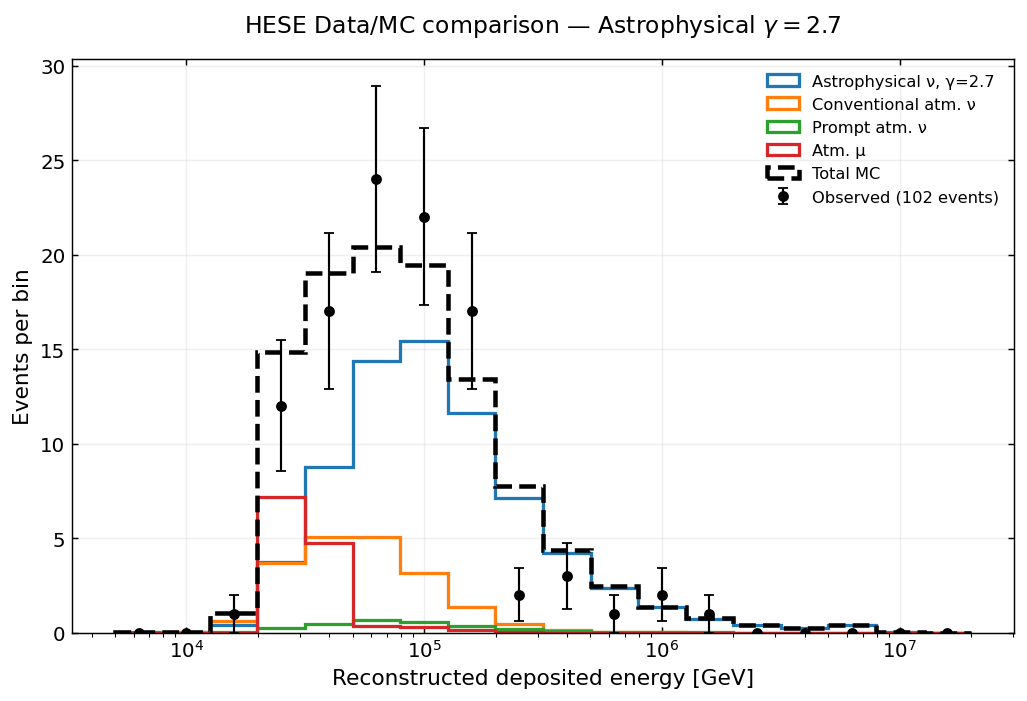

Figure saved to: output_plots/HESE_recoZenith_gamma_2.7.png


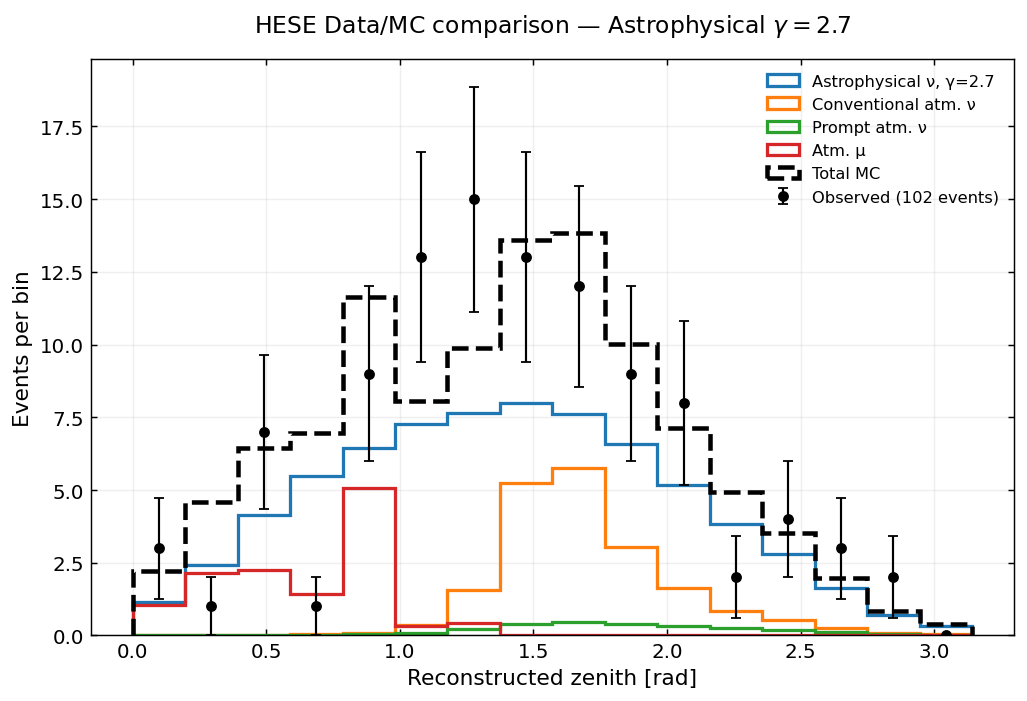

Figure saved to: output_plots/HESE_recoMorphology_gamma_2.7.png


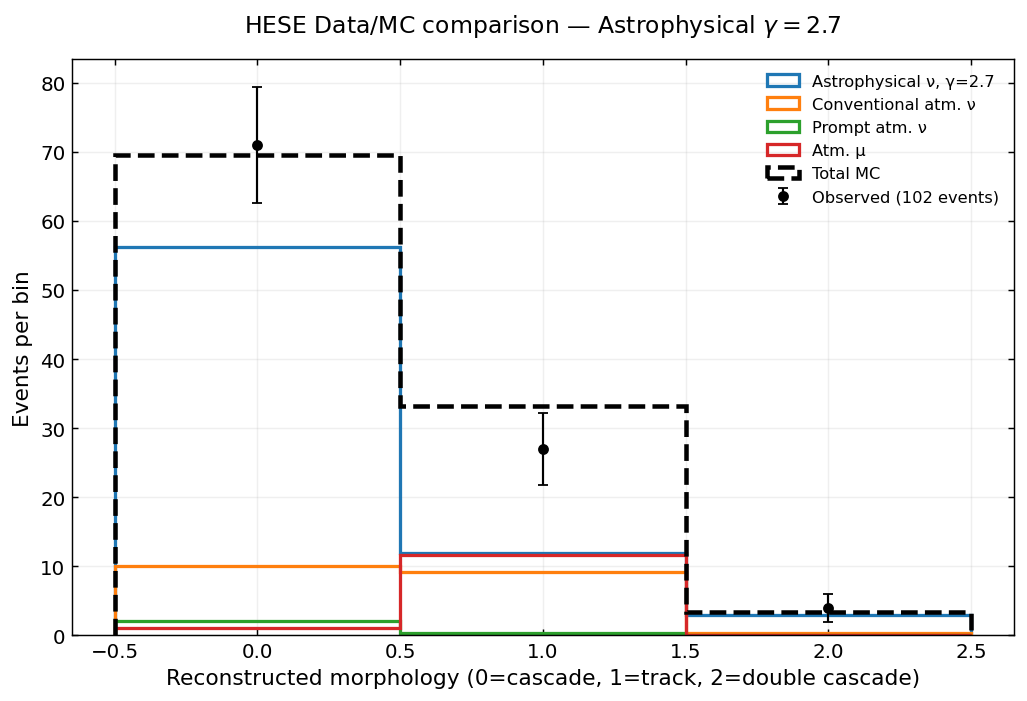

Figure saved to: output_plots/HESE_recoDepositedEnergy_gamma_2.png


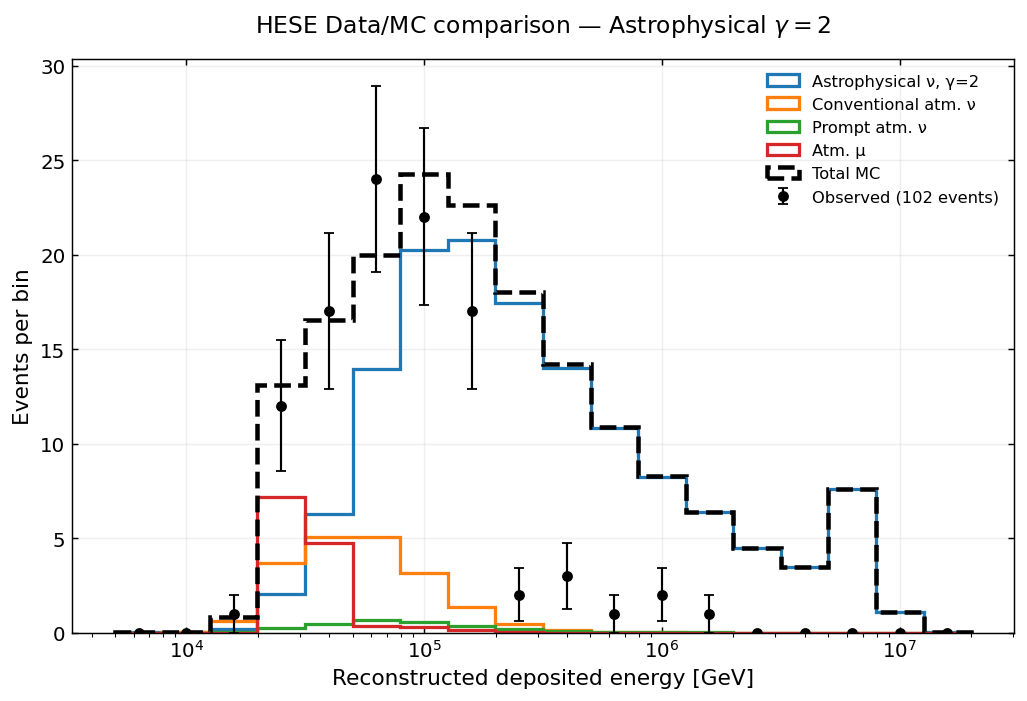

Figure saved to: output_plots/HESE_recoDepositedEnergy_gamma_3.8.png


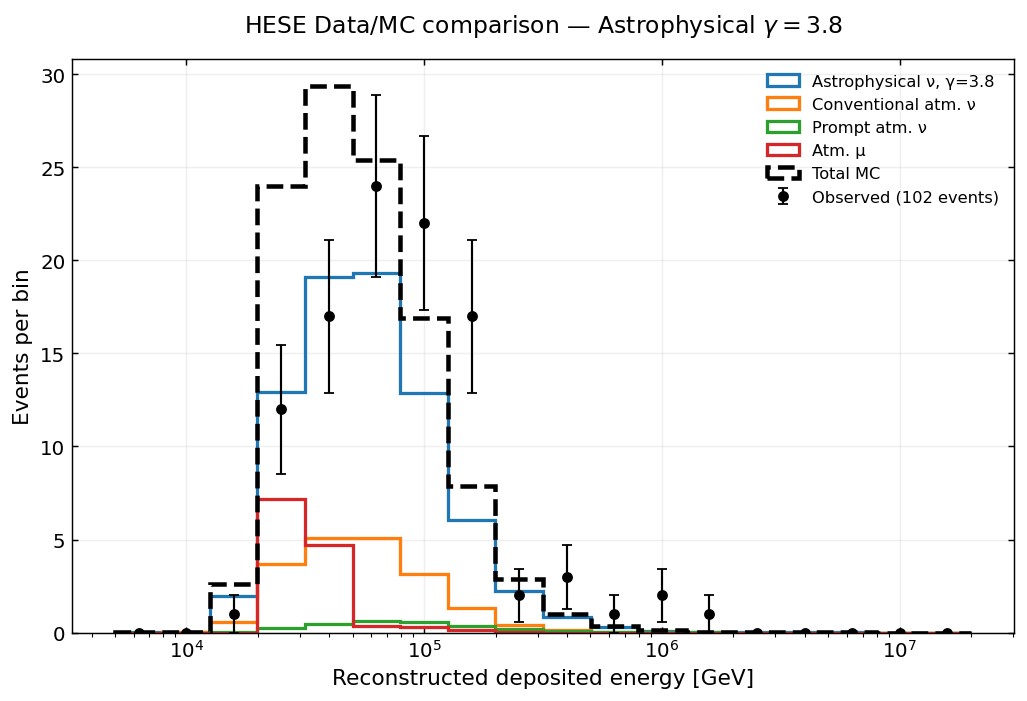

In [8]:
# Exercise 2 — Truth/reconstruction and observed-vs-predicted distributions
print('Observed events:', len(df_data), 'Selected MC entries:', len(df_mc))
print('Observed fields:', df_data.columns.tolist())
print('MC fields:', df_mc.columns.tolist())

print('\nObserved reconstructed quantities:')
print(df_data[['recoDepositedEnergy', 'recoZenith', 'recoMorphology']].describe())


# 1. Data/MC comparison for a reference spectral index
gamma = 2.7

# Compute expected event counts for each physical component
components = {
    f'Astrophysical ν, γ={gamma:g}': astro_counts(gamma),
    **background_counts()
}

# Total MC prediction (sum each component exactly once)
components['Total MC'] = np.sum(list(components.values()), axis=0)

print('\nComponent event expectations in the release livetime:')
for name, weights in components.items():
    print(f'{name:25s}: {weights.sum():.4g}')

# 2. Plot reconstructed quantities

# Logarithmic energy bins: 5 TeV to 20 PeV
energy_bins = np.geomspace(5e3, 2e7, 19)

plot_data_mc(
    'recoDepositedEnergy',
    energy_bins,
    components,
    'Reconstructed deposited energy [GeV]',
    logx=True,
    gamma=gamma,
    save=True
)

plot_data_mc(
    'recoZenith',
    np.linspace(0, np.pi, 17),
    components,
    'Reconstructed zenith [rad]',
    gamma=gamma,
    save=True
)

plot_data_mc(
    'recoMorphology',
    np.array([-0.5, 0.5, 1.5, 2.5]),
    components,
    'Reconstructed morphology (0=cascade, 1=track, 2=double cascade)',
    gamma=gamma,
    save=True
)

# 3. Compare different astrophysical spectral indices

# Investigate how changing gamma affects the detected
# reconstructed-energy distribution.
for gamma in [2.0, 3.8]:

    components_gamma = {
        f'Astrophysical ν, γ={gamma:g}': astro_counts(gamma),
        **background_counts()
    }

    components_gamma['Total MC'] = np.sum(
        list(components_gamma.values()), axis=0
    )

    plot_data_mc(
        'recoDepositedEnergy',
        energy_bins,
        components_gamma,
        'Reconstructed deposited energy [GeV]',
        logx=True,
        gamma=gamma,
        save=True
    )


**Instructor notes — Exercise 2 (essential).**

The `reco*` variables describe observed/reconstructed properties; the `primary*` fields in MC encode truth. The weighted prediction is the sum of the astrophysical component, conventional atmospheric neutrinos, prompt atmospheric neutrinos, and atmospheric muons. **Add `Total MC` only after collecting the physical components**—do not include it when summing again.

The data error bars use $\sqrt{n}$ as a convenient approximation. It is inadequate for low Poisson counts (especially $n=0$); exact or asymmetric Poisson intervals are more appropriate for quantitative work. With illustrative power-law parameters and nominal atmospheric normalizations, these plots demonstrate reweighting; they are **not a fitted HESE model**.


**Your discussion notes — Exercise 2:**  
*Write your interpretation here (a few sentences are enough).*

### Exercise 3 (essential) — what do the weights actually represent?

1. Using the units in the release README, show why `w0 × flux` is in $\mathrm{s^{-1}}$ and `T × w0 × flux` is dimensionless.
2. Compare raw MC `primaryEnergy` counts to weighted expected-event distributions for $\gamma=2,2.7,3.8$. Why does a raw MC histogram **not** represent the physical event rate?
3. Calculate `sum(astro_counts(γ))` for $\gamma=2,2.7,3.8$; split each sum into **below** and **above** $E_0=100\,\mathrm{TeV}$. Which index produces more events, and does a steeper spectrum always mean fewer?
4. Explain how changing the flux pivot, normalization, and true-energy acceptance influences the answer. Keep the same $\Phi(E_0)$ while changing $\gamma$.

 gamma  N expected  N (Etrue < 100 TeV)  N (Etrue >= 100 TeV)
     2       137.2                19.61                 117.6
   2.7       71.21                27.82                 43.38
   3.8       75.72                 56.4                 19.32


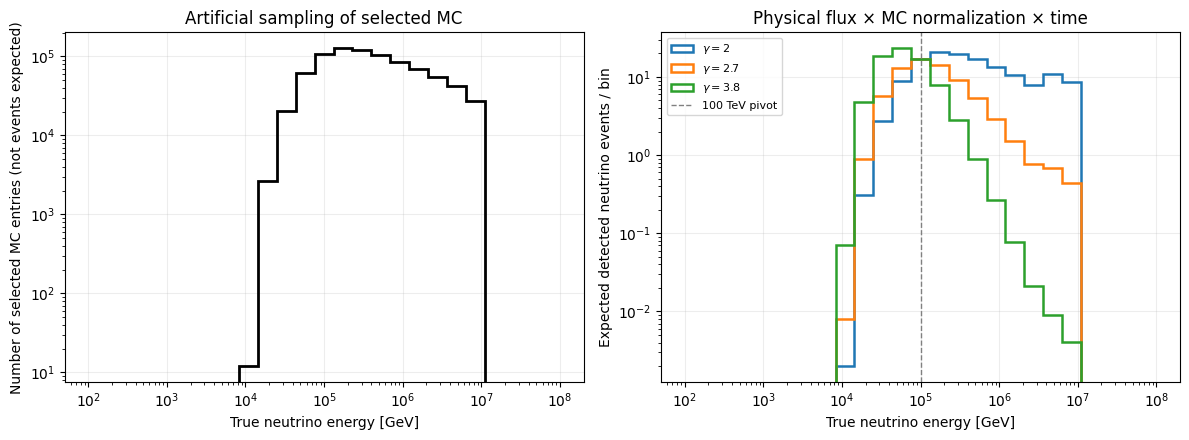

In [9]:
# Exercise 3 — raw selected MC entries versus physical counts
indices = [2.0, 2.7, 3.8]
rows = []
for gamma in indices:
    weights = astro_counts(gamma)
    rows.append({'gamma': gamma,
                 'N expected': weights.sum(),
                 'N (Etrue < 100 TeV)': weights[is_neutrino & (E_true < E0_GEV)].sum(),
                 'N (Etrue >= 100 TeV)': weights[is_neutrino & (E_true >= E0_GEV)].sum()})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f'{x:.4g}'))

true_bins = np.geomspace(1e2, 1e8, 26)
fig, (ax_raw, ax_phys) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_raw.hist(E_true[is_neutrino], bins=true_bins, histtype='step', lw=2, color='black')
ax_raw.set(xscale='log', yscale='log', xlabel=r'True neutrino energy [GeV]',
           ylabel='Number of selected MC entries (not events expected)',
           title='Artificial sampling of selected MC')
for gamma in indices:
    wg = astro_counts(gamma)
    ax_phys.hist(E_true[is_neutrino], bins=true_bins, weights=wg[is_neutrino],
                 histtype='step', lw=1.8, label=fr'$\gamma={gamma:g}$')
ax_phys.axvline(E0_GEV, color='grey', ls='--', lw=1, label='100 TeV pivot')
ax_phys.set(xscale='log', yscale='log', xlabel=r'True neutrino energy [GeV]',
            ylabel='Expected detected neutrino events / bin',
            title='Physical flux × MC normalization × time')
ax_phys.legend(fontsize=8)
fig.tight_layout()
output_dir = Path('output_plots')
output_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(output_dir / 'HESE_raw_vs_weighted_true_energy.png', dpi=300, bbox_inches='tight')
plt.show()

# At fixed Phi(E0), for E<E0 larger gamma raises the flux; for E>E0 it lowers it.
# Which gamma wins for the total is a property of both flux AND energy-dependent acceptance.


**Instructor notes — Exercise 3 (essential).**

Raw MC counts reflect the generation strategy and final sample selection, **not** a flux prediction. At fixed $\Phi(E_0)$, increasing $\gamma$ increases the flux **below** $E_0$ and decreases it **above** $E_0$. Therefore the total number of expected detected events does *not* have a universal ordering with $\gamma$: it depends on the true-energy acceptance and effective area.

If the pivot is changed while describing the **same** physical spectrum, the normalization must be transformed consistently. Changing the pivot but keeping the same numerical normalization instead changes the physical model.


**Your discussion notes — Exercise 3:**  
*Write your interpretation here (a few sentences are enough).*

### Exercise 4 (essential) — atmospheric versus astrophysical fluxes

1. Plot `pionFlux`, `kaonFlux`, `promptFlux` against MC **true neutrino energy**. Compare them with astrophysical hypotheses $\Phi_0(E/E_0)^{-\gamma}$, $\gamma=2,2.7,3.8$. State units.
2. Why is there a **spread** of atmospheric flux values at the same energy? Test a restricted band in true zenith. The HESE arrays contain **event-wise flux evaluated at each MC truth configuration**, not a direction-independent 1-D flux table.
3. Now turn flux into predicted detected events: apply the **appropriate veto passing fractions** to conventional/prompt atmospheric neutrinos and multiply by `w0 × T`. Add atmospheric muons using their *separate* weight. What happens if prompt is multiplied by 0, 1, and 3?

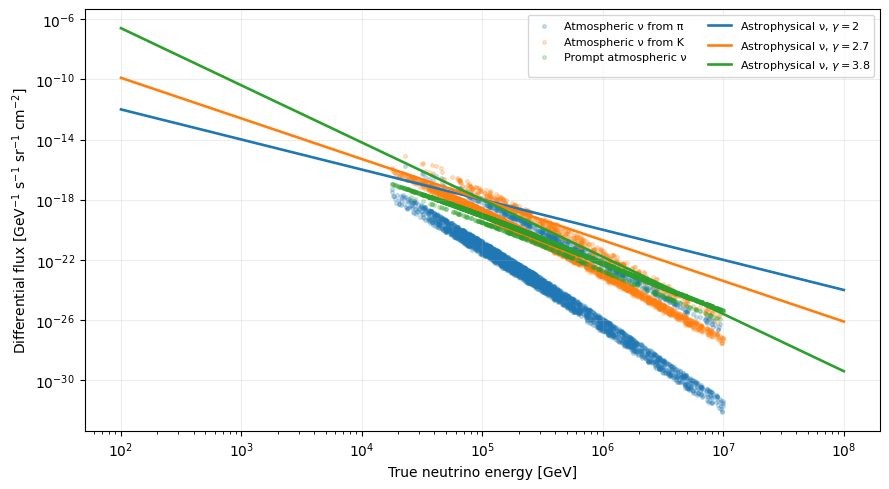

Prompt normalization x0: {'Conventional atm. ν': 19.547, 'Prompt atm. ν': 0.0, 'Atm. μ': 12.71}
Prompt normalization x1: {'Conventional atm. ν': 19.547, 'Prompt atm. ν': 2.589, 'Atm. μ': 12.71}
Prompt normalization x3: {'Conventional atm. ν': 19.547, 'Prompt atm. ν': 7.768, 'Atm. μ': 12.71}
With self-veto corrections: {'Conventional atm. ν': 19.547, 'Prompt atm. ν': 2.589, 'Atm. μ': 12.71}
Without self-veto corrections (comparison only): {'Conventional atm. ν': 25.815, 'Prompt atm. ν': 4.337, 'Atm. μ': 12.71}


In [10]:
# Exercise 4 — event-wise atmospheric fluxes versus assumed astrophysical fluxes
true_coszen = np.cos(df_mc['primaryZenith'].to_numpy(float))
zenith_slice = is_neutrino & np.isfinite(true_coszen) & (np.abs(true_coszen) < 0.25)
rng = np.random.default_rng(7)  # reproducible, avoids drawing all MC points
valid_indices = np.flatnonzero(zenith_slice)
subset = rng.choice(valid_indices, size=min(3500, len(valid_indices)), replace=False)
fig, ax = plt.subplots(figsize=(9, 5))
for field, label in [('pionFlux', 'Atmospheric ν from π'),
                     ('kaonFlux', 'Atmospheric ν from K'),
                     ('promptFlux', 'Prompt atmospheric ν')]:
    values = df_mc[field].to_numpy(float)[subset]
    good = np.isfinite(values) & (values > 0)
    ax.scatter(E_true[subset][good], values[good], s=7, alpha=.22, label=label)
energy_grid = np.geomspace(1e2, 1e8, 250)
for gamma in [2.0, 2.7, 3.8]:
    ax.plot(energy_grid, astro_flux(energy_grid, gamma), lw=1.9,
            label=fr'Astrophysical ν, $\gamma={gamma:g}$')
ax.set(xscale='log', yscale='log', xlabel=r'True neutrino energy [GeV]',
       ylabel=r'Differential flux [GeV$^{-1}$ s$^{-1}$ sr$^{-1}$ cm$^{-2}$]')
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
output_dir = Path('output_plots')
output_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(output_dir / 'HESE_atmospheric_vs_astrophysical_fluxes.png', dpi=300, bbox_inches='tight')
plt.show()

# The event-wise atmospheric fluxes are not the event counts: apply weights, livetime and veto.
for prompt_scale in [0., 1., 3.]:
    components_atm = background_counts(prompt_scale=prompt_scale, self_veto=True)
    print(f'Prompt normalization x{prompt_scale:g}:',
          {key: round(float(value.sum()), 3) for key, value in components_atm.items()})
print('With self-veto corrections:',
      {k: round(float(v.sum()), 3) for k, v in background_counts().items()})
print('Without self-veto corrections (comparison only):',
      {k: round(float(v.sum()), 3) for k, v in background_counts(self_veto=False).items()})

# Sanity check: conventional = (π + K) × conventional veto × w0 × T, neutrinos only.
manual_conventional = np.where(
    is_neutrino,
    T*w0*(df_mc['pionFlux'].to_numpy(float) + df_mc['kaonFlux'].to_numpy(float))
    *df_mc['conventionalSelfVetoCorrection'].to_numpy(float), 0.)
np.testing.assert_allclose(np.nan_to_num(manual_conventional),
                           background_counts()['Conventional atm. ν'])


**Instructor notes — Exercise 4 (essential).**

`pionFlux`, `kaonFlux`, and `promptFlux` are event-wise flux values evaluated at MC true energy, direction and species. They are not weighted event counts and will show scatter even at fixed energy. Conventional atmospheric flux is `pionFlux + kaonFlux` and uses `conventionalSelfVetoCorrection`. Prompt flux uses `promptSelfVetoCorrection`. The passing fractions account for atmospheric-neutrino self-veto effects in the HESE selection; they do not apply to astrophysical neutrinos.

Atmospheric muons are simulated separately and use `muonWeightOverLivetime`; multiplying by a neutrino flux would be incorrect. The `prompt_scale` variation illustrates changes in the physical model normalization without simulating a new detector.


**Your discussion notes — Exercise 4:**  
*Write your interpretation here (a few sentences are enough).*

## C. Detector response — what can we really derive?

The public HESE MC contains events **after the HESE selection**, with their true and reconstructed quantities.

- In **Exercise 5**, use the generator-normalization information encoded in `weightOverFluxOverLivetime` to estimate the *selected-sample effective area*. It is not the trigger-level effective area.
- In **Exercise 6**, characterize how reconstructed **deposited** energy compares with true neutrino energy using weighted residual quantiles. These reflect interaction and containment effects as well as reconstruction.
- In **Exercise 7**, inspect which directional coordinates are provided and decide which angular-response quantities can be measured from the available columns.

Do not interpret an additional-cut efficiency relative to the HESE sample as a full trigger efficiency. The optional exercises are useful extensions but are **not required to finish the 90-minute core session**.


### Exercise 5 — Derive the selected-sample HESE effective area (essential)

Use the `weightOverFluxOverLivetime` field to estimate the sky-averaged effective area as a function of **true neutrino energy**.

**Your tasks:**

1. Check the units of `weightOverFluxOverLivetime`. Starting from its units, derive how to calculate $A_{\rm eff}$ by summing MC normalization weights in a bin of width $\Delta E$ and solid angle $\Delta\Omega$.
2. Select one neutrino PDG species, e.g. `primaryType == 14` for $\nu_\mu$. For a full-sky average, use $\Delta\Omega=4\pi$ sr. Plot the result in m². Do not weight by an astrophysical flux or multiply by the livetime.
3. Repeat for $\bar\nu_\mu$ (`primaryType == -14`) and show the **sum of the two species' effective areas** on the same plot.
4. Discuss why the two species might differ. Does the effective area itself change if you change the astrophysical spectral index $\gamma$?

**Hints:** You can use `np.histogram(..., weights=...)` to sum weights in true-energy bins, and `np.diff()` to obtain bin widths. Use `np.nan` for empty bins on a logarithmic axis. Remember that the sum of species-specific areas is not automatically the same as an area averaged over a combined neutrino + antineutrino flux.


$\nu_\mu$: 108834 selected MC events
$\bar{\nu}_\mu$: 105902 selected MC events


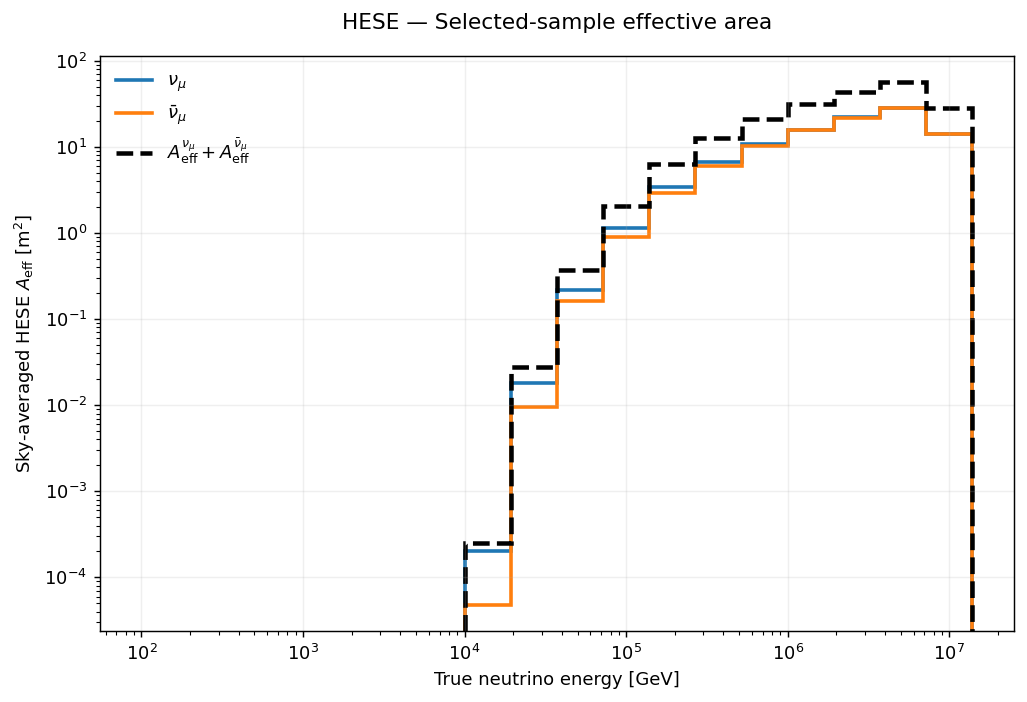

In [11]:
# Exercise 5 — HESE selected-sample effective area
pdg = df_mc['primaryType'].to_numpy(int)

# True neutrino energy bins [GeV]
e_edges = np.geomspace(1e2, 1e8, 22)
delta_E = np.diff(e_edges)
delta_Omega = 4 * np.pi  # Full-sky solid angle [sr]

fig, ax = plt.subplots(figsize=(8, 5.5), dpi=130)

effective_areas = {}

# Calculate A_eff separately for ν_mu and anti-ν_mu
for species, label in [
    (14, r'$\nu_\mu$'),
    (-14, r'$\bar{\nu}_\mu$')
]:

    # Select the neutrino species
    sel = is_neutrino & (pdg == species)

    # Sum MC normalization weights in true-energy bins
    sum_w0, _ = np.histogram(
        E_true[sel],
        bins=e_edges,
        weights=w0[sel]
    )

    # Sky-averaged effective area [m²]
    # Do not multiply by flux or livetime
    ae_m2 = sum_w0 / (delta_E * delta_Omega * 1e4)

    effective_areas[species] = ae_m2

    ax.stairs(
        np.where(ae_m2 > 0, ae_m2, np.nan),
        e_edges,
        linewidth=2,
        label=label
    )

    print(f'{label}: {sel.sum()} selected MC events')

# Sum of neutrino and antineutrino effective areas
ae_sum = effective_areas[14] + effective_areas[-14]

ax.stairs(
    np.where(ae_sum > 0, ae_sum, np.nan),
    e_edges,
    color='black',
    linewidth=2.5,
    linestyle='--',
    label=r'$A_{\rm eff}^{\nu_\mu}+A_{\rm eff}^{\bar{\nu}_\mu}$'
)

# Plot appearance
ax.set(
    xscale='log',
    yscale='log',
    xlabel='True neutrino energy [GeV]',
    ylabel=r'Sky-averaged HESE $A_{\rm eff}$ [m$^2$]'
)

ax.set_title('HESE — Selected-sample effective area', pad=15)
ax.legend(frameon=False)
ax.grid(True, which='major', alpha=0.2)

fig.tight_layout()

# Save figure
output_dir = Path('output_plots')
output_dir.mkdir(parents=True, exist_ok=True)

filename = output_dir / 'HESE_effective_area_numu_antinu_sum.png'
fig.savefig(filename, dpi=300, bbox_inches='tight')
plt.show()


**Instructor notes — Exercise 5 (essential).**

For one selected neutrino species, the full-sky-averaged area in a true-energy bin is $\sum w_{0,i}/(4\pi\,\Delta E)$ in cm² (divide by $10^4$ to obtain m²). Use `w0` directly: **do not multiply by flux, time, or divide again by simulated sample size**. The public data encode the **final HESE selection**, not a trigger-only area.

The black curve is the **sum of the two species-specific effective areas**. If a physical flux is specified *per particle species*, this sum times that flux is appropriate; if a plotted flux is the combined $\nu_\mu+\bar\nu_\mu$ flux under a 50/50 mixture, the appropriate average area is half the sum. Neutrino and antineutrino areas can differ through cross sections, absorption, and event selection. The effective area does not depend on the chosen astrophysical $\gamma$.


**Your discussion notes — Exercise 5:**  
*Write your interpretation here (a few sentences are enough).*

### Optional extension — Effect of additional selections on the effective area

The HESE Monte Carlo sample already includes events that have passed the HESE event selection. However, we can investigate how applying **additional selection criteria** affects the detector's effective area.

**Your tasks:**

1. Starting from the effective area calculated in Exercise 5, apply additional cuts on reconstructed quantities, for example:
   - **Energy:** `recoDepositedEnergy >= 100 TeV` (remember to convert to GeV).
   - **Event topology:** select only track-like events using `recoMorphology`.
   - **Direction:** select upgoing or downgoing events using `recoZenith`.
   - **Event length:** apply a minimum reconstructed length using `recoLength`.

2. Recalculate the effective area after each selection and compare it with the original HESE effective area on the same plot.

3. Calculate the ratio between the effective area after the additional selection and the original one:

   $$
   \epsilon_{\mathrm{additional}}(E_\nu) =
   \frac{A_{\mathrm{eff}}^{\mathrm{after\ cut}}(E_\nu)}
   {A_{\mathrm{eff}}^{\mathrm{original}}(E_\nu)}
   $$

   What does this ratio represent? Consider only energy bins with sufficient MC statistics.

**Discussion questions:**

- Which selection has the largest impact on the effective area?
- How does the effect of each selection depend on the true neutrino energy?
- Why might selecting only track-like events significantly reduce the effective area, even for muon neutrinos?
- How do the effective areas differ between upgoing and downgoing events?
- Why does a cut on **reconstructed** energy affect the effective area as a function of **true** energy?
- Can the effective area at trigger level be recovered from the publicly available HESE MC sample? Why or why not?

**Important:** The ratio above describes the efficiency of an **additional cut relative to the already-selected HESE sample**, not the overall detector trigger or event-selection efficiency.

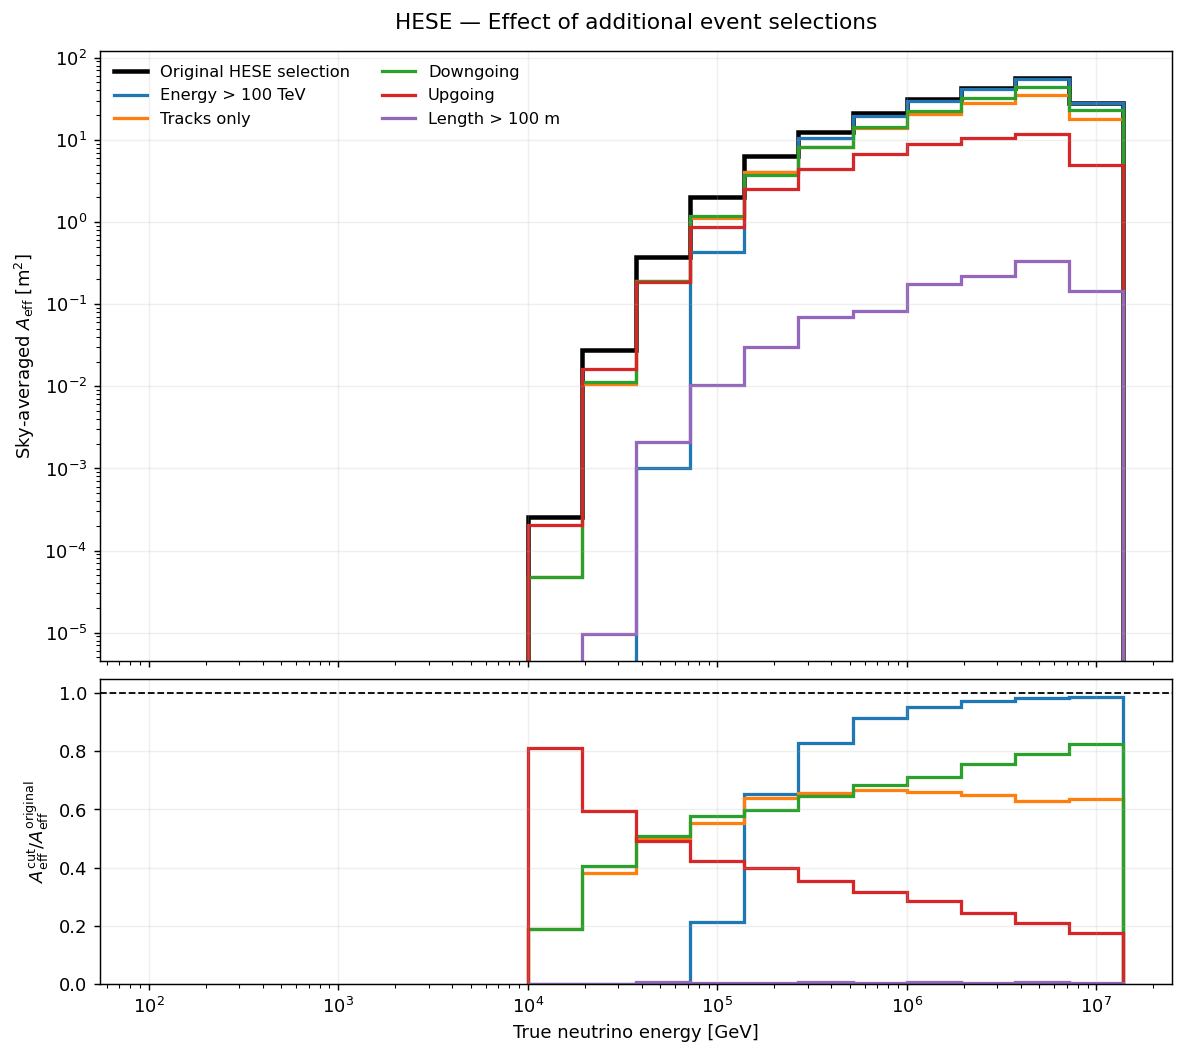

Plot saved to: output_plots/HESE_effective_area_cuts_and_ratios.png


In [12]:

# Exercise 5 — Effect of additional selections on the HESE effective area
E_dep = df_mc['recoDepositedEnergy'].to_numpy(float)
reco_zenith = df_mc['recoZenith'].to_numpy(float)
reco_morph = df_mc['recoMorphology'].to_numpy(float)
reco_length = df_mc['recoLength'].to_numpy(float)

# Baseline: selected HESE muon neutrinos and antineutrinos
baseline = is_neutrino & np.isin(pdg, [14, -14])

# Additional selections to investigate
cuts = {
    "Energy > 100 TeV": E_dep >= 1e5,
    "Tracks only": reco_morph == 1,
    "Downgoing": reco_zenith < np.pi / 2,
    "Upgoing": reco_zenith >= np.pi / 2,
    "Length > 100 m": reco_length >= 100,
}

# Two panels: effective area and relative efficiency
fig, (ax, ax_ratio) = plt.subplots(
    2, 1,
    figsize=(9, 8),
    sharex=True,
    gridspec_kw={'height_ratios': [3, 1.5]},
    layout='constrained',
    dpi=130
)

# Original effective area: ν_mu + anti-ν_mu
ax.stairs(
    np.where(ae_sum > 0, ae_sum, np.nan),
    e_edges,
    color='black',
    linewidth=2.5,
    label='Original HESE selection'
)

# Calculate effective area and ratio for each additional cut
for label, cut in cuts.items():

    selected = baseline & cut & np.isfinite(E_true)

    # Sum the MC normalization weights in true-energy bins
    sum_w, _ = np.histogram(
        E_true[selected],
        bins=e_edges,
        weights=w0[selected]
    )

    # Sky-averaged effective area [m^2]
    ae_cut = sum_w / (np.diff(e_edges) * 4*np.pi * 1e4)

    # Ratio to original HESE effective area
    # Undefined where the baseline effective area is zero
    ratio = np.divide(
        ae_cut,
        ae_sum,
        out=np.full_like(ae_sum, np.nan),
        where=ae_sum > 0
    )

    # Upper panel: effective area
    line = ax.stairs(
        np.where(ae_cut > 0, ae_cut, np.nan),
        e_edges,
        linewidth=1.8,
        label=label
    )

    # Lower panel: efficiency relative to released HESE sample
    ax_ratio.stairs(
        ratio,
        e_edges,
        color=line.get_edgecolor(),
        linewidth=1.8
    )

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylabel(r'Sky-averaged $A_{\rm eff}$ [m$^2$]')
ax.set_title('HESE — Effect of additional event selections', pad=12)

ax.legend(frameon=False, fontsize=9, ncol=2)
ax.grid(True, alpha=0.2)

ax_ratio.set_xscale('log')
ax_ratio.set_ylim(0, 1.05)
ax_ratio.set_xlabel('True neutrino energy [GeV]')
ax_ratio.set_ylabel(r'$A_{\rm eff}^{\rm cut}/A_{\rm eff}^{\rm original}$')

ax_ratio.axhline(1, color='black', linestyle='--', linewidth=1)
ax_ratio.grid(True, alpha=0.2)

# Save figure
output_dir = Path('output_plots')
output_dir.mkdir(parents=True, exist_ok=True)

filename = output_dir / 'HESE_effective_area_cuts_and_ratios.png'
fig.savefig(filename, dpi=300, bbox_inches='tight')
plt.show()

print(f'Plot saved to: {filename}')


**Instructor notes — Additional cuts (optional).**

For every cut, compute the newly selected area using the same `w0`, true-energy binning and $4\pi$ denominator as the original. The ratio $A_{\rm eff}^{\rm cut}/A_{\rm eff}^{\rm baseline}$ estimates the **acceptance of the additional cut conditional on having passed HESE**, within the chosen true-energy bin and species mixture. It cannot recover trigger-level efficiency.

`recoZenith` is a reconstructed direction; selecting upgoing/downgoing events does not turn this into an area restricted to a true-sky solid angle. The chosen denominator remains $4\pi$ because the plot is a sky-averaged acceptance *after a reconstructed-direction cut*. Empty or low-effective-MC-statistics bins should not be over-interpreted.


### Optional Exercise 6 — Reconstructed deposited-energy response and bias

In this exercise, we investigate how the reconstructed deposited energy relates to the true neutrino energy.

In an ideal detector with perfect energy reconstruction, we might expect the reconstructed energy to match the true energy. However, in neutrino telescopes, not all the neutrino energy is necessarily deposited and detected.

For example, some energy may be carried away by outgoing neutrinos, while secondary particles may escape the detector volume.

We define the following quantity:

$$
\delta=
\log_{10}\left(\frac{E_{\mathrm{dep,reco}}}{E_{\nu,\mathrm{true}}}\right)
$$

where:
- $E_{\nu,\mathrm{true}}$ is the true neutrino energy (`primaryEnergy`).
- $E_{\mathrm{dep,reco}}$ is the reconstructed deposited energy (`recoDepositedEnergy`).

If $\delta=0$, the reconstructed deposited energy equals the true neutrino energy. Negative values indicate that the reconstructed deposited energy is smaller than the true neutrino energy.

To characterize the response, we use **weighted quantiles** in bins of true neutrino energy:

- **Median (50th percentile):** describes the central tendency of the energy residual and can be used to characterize its bias.
- **16th and 84th percentiles:** define the central 68% interval, describing the spread of the response.

For a Gaussian distribution, this interval corresponds approximately to $\pm 1\sigma$. However, energy-response distributions are not necessarily Gaussian.

#### Your tasks

1. Calculate $\delta$ for simulated neutrino events using `primaryEnergy` and `recoDepositedEnergy`.

2. Divide the events into bins of true neutrino energy. For each bin, calculate the **weighted median** and the **16th and 84th percentiles** of $\delta$.

3. Plot these quantities as a function of true neutrino energy, comparing two astrophysical spectral indices: $\gamma=2.0$ and $\gamma=3.8$.

4. **Discussion:**
   - Is the median residual always zero? Why or why not?
   - Does the spread of the response change with energy?
   - Why does the difference between true neutrino energy and reconstructed deposited energy include physical interaction effects in addition to reconstruction uncertainties?
   - Do the weighted quantiles change when using different spectral indices? Why might this happen?

**Important:** This is not a measurement of the intrinsic neutrino-energy resolution alone. The distribution also includes the effects of neutrino interactions, invisible or escaping energy, and event selection.

Plot saved to: output_plots/HESE_energy_response_gamma_comparison.png


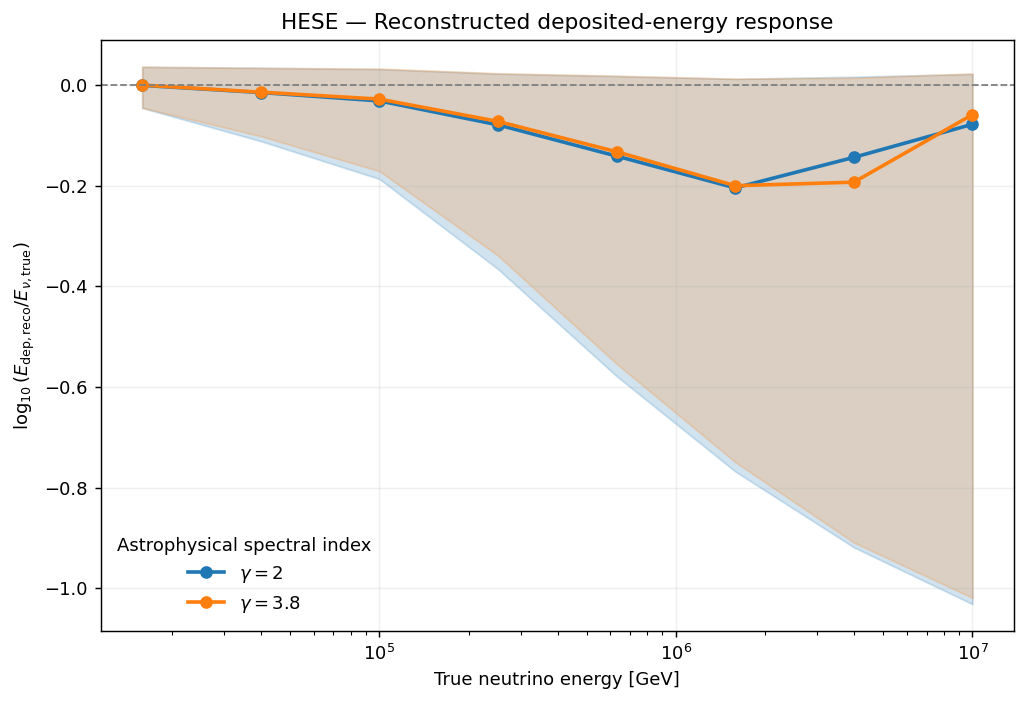

In [13]:
# Exercise 6 — Reconstructed energy response and bias

# True neutrino energy and reconstructed deposited energy
E_dep = df_mc['recoDepositedEnergy'].to_numpy(float)

# Select neutrino events with valid energies
good = is_neutrino & np.isfinite(E_dep) & (E_dep > 0)

E_true_nu = E_true[good]
E_dep_nu = E_dep[good]

# Energy residual: log10(Edep,reco / Eν,true)
delta = np.log10(E_dep_nu / E_true_nu)

# Define logarithmic bins in true neutrino energy
true_edges = np.geomspace(1e2, 1e8, 16)
centers = np.sqrt(true_edges[:-1] * true_edges[1:])

fig, ax = plt.subplots(figsize=(8, 5.5), dpi=130)

# Compare two astrophysical spectral indices
for gamma in [2.0, 3.8]:

    # Expected event weights for the chosen spectrum
    weights = astro_counts(gamma)[good]

    quantiles = []

    # Compute weighted quantiles in each true-energy bin
    for lo, hi in zip(true_edges[:-1], true_edges[1:]):

        in_bin = (E_true_nu >= lo) & (E_true_nu < hi)

        q16, q50, q84 = weighted_quantile(
            delta[in_bin],
            weights[in_bin],
            [0.16, 0.50, 0.84]
        )

        quantiles.append([q16, q50, q84])

    quantiles = np.asarray(quantiles)

    # Plot median and central 68% interval
    line, = ax.plot(
        centers,
        quantiles[:, 1],
        marker='o',
        linewidth=2,
        label=fr'$\gamma={gamma:g}$'
    )

    ax.fill_between(
        centers,
        quantiles[:, 0],
        quantiles[:, 2],
        color=line.get_color(),
        alpha=0.2
    )

# Reference line: reconstructed deposited energy = true energy
ax.axhline(0, linestyle='--', color='gray', linewidth=1)

ax.set_xscale('log')
ax.set_xlabel('True neutrino energy [GeV]')
ax.set_ylabel(
    r'$\log_{10}(E_{\mathrm{dep,reco}}/E_{\nu,\mathrm{true}})$'
)

ax.set_title('HESE — Reconstructed deposited-energy response')
ax.legend(title='Astrophysical spectral index', frameon=False)
ax.grid(True, alpha=0.2)
fig.tight_layout()

output_dir = Path("output_plots")
output_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(
    output_dir / "HESE_energy_response_gamma_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

print(f"Plot saved to: {output_dir / 'HESE_energy_response_gamma_comparison.png'}")

plt.show()


**Instructor notes — Exercise 6 (optional).**

The residual $\delta=\log_{10}(E_{\rm dep,reco}/E_{\nu,\rm true})$ compares **reconstructed deposited energy with incoming neutrino energy**. A negative median is not automatically a reconstruction failure: invisible energy, outgoing particles, containment, interaction channel, and reconstruction all contribute. Therefore the central 68% interval is a measure of this **combined deposited-energy response**, not intrinsic neutrino-energy resolution alone.

The 16th, 50th, and 84th weighted quantiles summarize the conditional distribution of *selected* events in finite true-energy bins. They can change when $\gamma$ changes because reweighting alters which energies and topologies dominate *within a finite bin*. They are not properties of a hypothetical perfectly conditioned detector response alone.


### Optional Exercise 7 — Angular resolution: what can we learn from HESE? 

In neutrino astronomy, the **angular resolution** describes how accurately a detector reconstructs the arrival direction of a neutrino.

It is particularly important for point-source searches, where we want to associate a detected neutrino with a possible astrophysical source.

The angular response of a detector is often characterized by the **Point Spread Function (PSF)**, which describes the distribution of reconstructed directions around the true direction.

#### Your tasks

1. Inspect the variables available in the HESE Monte Carlo sample.

   - Which variables describe the true and reconstructed event directions?
   - Do you have all the information needed to calculate the angular separation between the true and reconstructed directions?
   - Can you derive the full angular resolution or PSF from this dataset? Why or why not?

2. **Investigate what can be calculated with the available information.**

   Using `primaryZenith` and `recoZenith`, define the zenith reconstruction residual:

   $$
   \Delta\theta = \theta_{\mathrm{reco}}-\theta_{\mathrm{true}}.
   $$

   Plot the weighted distribution of $\Delta\theta$ (in degrees) for simulated neutrino events.

3. **Optional extension:** Study the zenith reconstruction performance as a function of true neutrino energy.

   - Divide the MC events into bins of `primaryEnergy`.
   - Calculate the weighted median and 16th–84th percentile interval of $\Delta\theta$ in each bin.
   - Plot these quantities as a function of true neutrino energy.
   - Compare track-like and cascade-like events, if sufficient MC statistics are available.

#### Discussion

- What does the median zenith residual tell us?
- Why might tracks and cascades have different directional reconstruction performances?
- Why is the zenith reconstruction residual not equivalent to the full angular separation between the true and reconstructed neutrino directions?
- What additional information would be necessary to construct a PSF?

**Important:** The zenith residual characterizes only one component of the directional reconstruction. It should not be interpreted as the detector's full angular resolution or PSF.

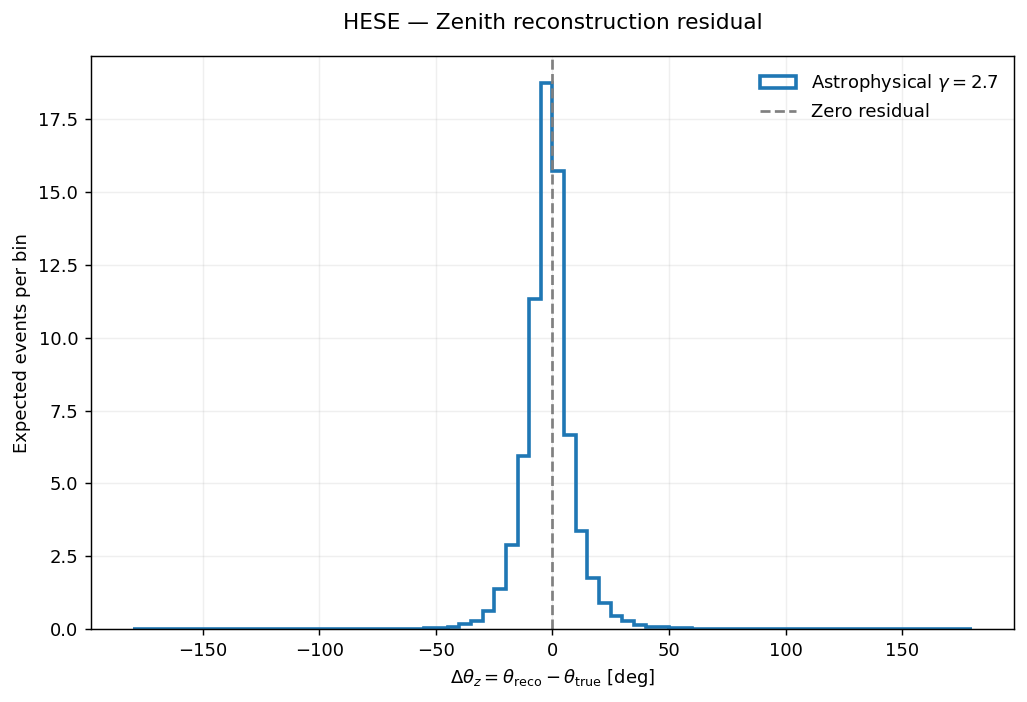

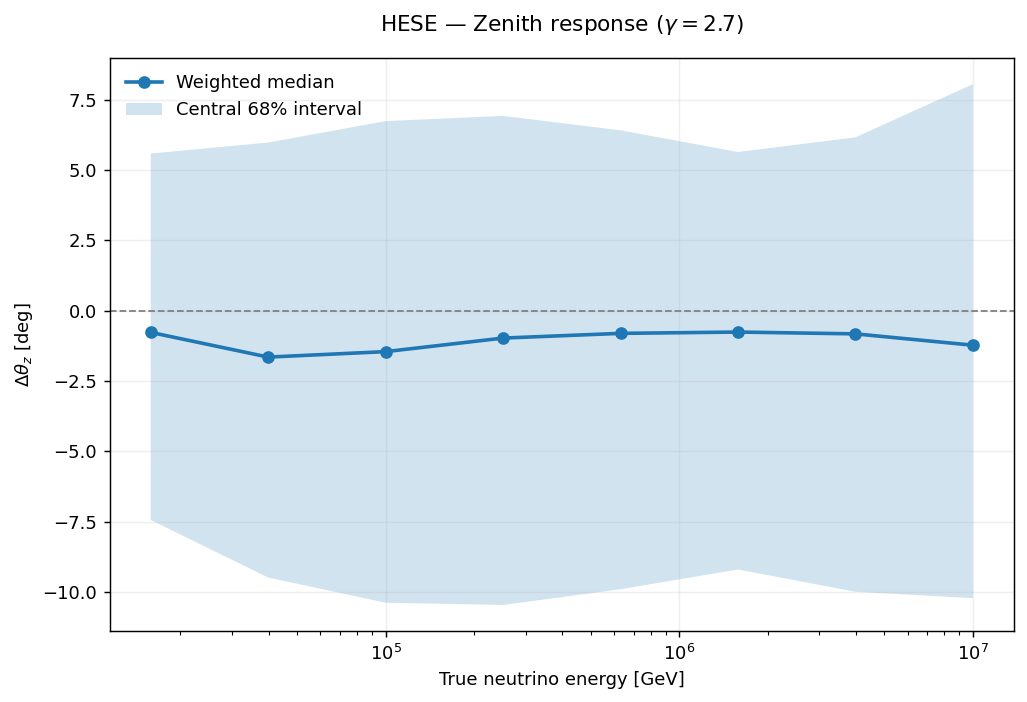

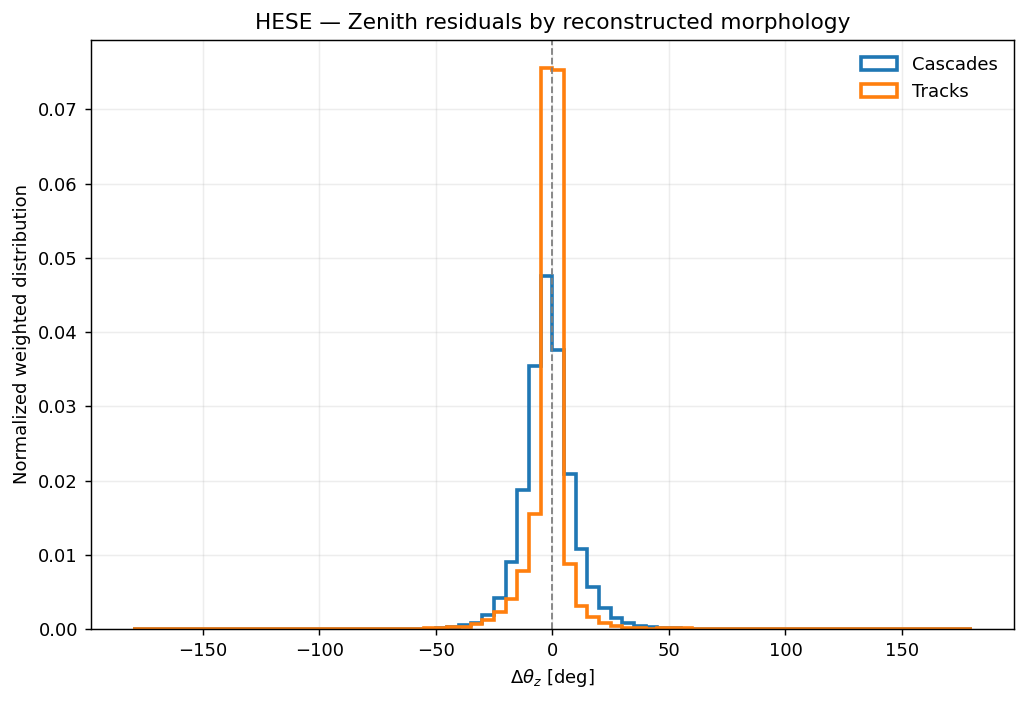

In [14]:
# Exercise 7 — Zenith angular response

# The public HESE sample contains true and reconstructed
# zenith angles, but not the corresponding azimuth angles.
# Therefore, we can study the ZENITH reconstruction response,
# but not the full angular resolution or PSF.

# 1. Calculate the zenith reconstruction residual
zenith_true = df_mc['primaryZenith'].to_numpy(float)
zenith_reco = df_mc['recoZenith'].to_numpy(float)

# Select neutrino events with valid zenith angles
good = (
    is_neutrino
    & np.isfinite(zenith_true)
    & np.isfinite(zenith_reco)
    & (zenith_true >= 0) & (zenith_true <= np.pi)
    & (zenith_reco >= 0) & (zenith_reco <= np.pi)
)

# Zenith reconstruction residual [degrees]
delta_zenith = np.degrees(zenith_reco[good] - zenith_true[good])

# Expected astrophysical event weights
gamma = 2.7
weights = astro_counts(gamma)[good]


# 2. Plot the weighted zenith residual distribution
fig, ax = plt.subplots(figsize=(8, 5.5), dpi=130)

ax.hist(
    delta_zenith,
    bins=np.linspace(-180, 180, 73),
    weights=weights,
    histtype='step',
    linewidth=2,
    label=fr'Astrophysical $\gamma={gamma:g}$'
)

# Perfect zenith reconstruction corresponds to Delta theta = 0
ax.axvline(0, color='gray', linestyle='--',
           linewidth=1.5, label='Zero residual')

ax.set_xlabel(r'$\Delta\theta_z = \theta_{\rm reco}-\theta_{\rm true}$ [deg]')
ax.set_ylabel('Expected events per bin')

ax.set_title('HESE — Zenith reconstruction residual', pad=15)
ax.legend(frameon=False)
ax.grid(True, alpha=0.2)

fig.tight_layout()

# Save plot
output_dir = Path('output_plots')
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / 'HESE_zenith_residual.png',
    dpi=300, bbox_inches='tight'
)
plt.show()

# 3. Zenith response as a function of true neutrino energy
E_true_nu = E_true[good]

# Logarithmic true-energy bins
energy_edges = np.geomspace(1e2, 1e8, 16)
energy_centers = np.sqrt(energy_edges[:-1] * energy_edges[1:])

quantiles = []

# Calculate weighted quantiles in each true-energy bin
for lo, hi in zip(energy_edges[:-1], energy_edges[1:]):

    in_bin = (E_true_nu >= lo) & (E_true_nu < hi)

    q16, q50, q84 = weighted_quantile(
        delta_zenith[in_bin],
        weights[in_bin],
        [0.16, 0.50, 0.84]
    )

    quantiles.append([q16, q50, q84])

quantiles = np.asarray(quantiles)

fig, ax = plt.subplots(figsize=(8, 5.5), dpi=130)

# Weighted median: central tendency of the zenith residual
ax.plot(
    energy_centers,
    quantiles[:, 1],
    marker='o',
    linewidth=2,
    label='Weighted median'
)

# Central 68% interval
ax.fill_between(
    energy_centers,
    quantiles[:, 0],
    quantiles[:, 2],
    alpha=0.2,
    label='Central 68% interval'
)

ax.axhline(0, color='gray', linestyle='--', linewidth=1)

ax.set_xscale('log')
ax.set_xlabel('True neutrino energy [GeV]')
ax.set_ylabel(r'$\Delta\theta_z$ [deg]')

ax.set_title(
    fr'HESE — Zenith response ($\gamma={gamma:g}$)',
    pad=15
)

ax.legend(frameon=False)
ax.grid(True, alpha=0.2)

fig.tight_layout()

# Save plot
fig.savefig(
    output_dir / 'HESE_zenith_response_vs_energy.png',
    dpi=300, bbox_inches='tight'
)

plt.show()

# OPTIONAL — Compare the shape of the zenith-residual distribution
# between reconstructed tracks and cascades.
reco_morphology = df_mc['recoMorphology'].to_numpy(float)[good]
fig, ax = plt.subplots(figsize=(8, 5.5), dpi=130)
for code, label in [(0, 'Cascades'), (1, 'Tracks')]:
    selected = (reco_morphology == code)
    if not np.any(selected) or weights[selected].sum() <= 0:
        continue
    ax.hist(delta_zenith[selected], bins=np.linspace(-180, 180, 73),
            weights=weights[selected], density=True,
            histtype='step', linewidth=2, label=label)
ax.axvline(0, ls='--', color='gray', lw=1)
ax.set(xlabel=r'$\Delta\theta_z$ [deg]',
       ylabel='Normalized weighted distribution',
       title='HESE — Zenith residuals by reconstructed morphology')
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(output_dir / 'HESE_zenith_residual_tracks_vs_cascades.png',
            dpi=300, bbox_inches='tight')
plt.show()


**Instructor notes — Exercise 7 (optional).**

The public MC has `primaryZenith` and `recoZenith` but does **not** supply the corresponding true and reconstructed azimuths. Computing the full opening angle requires both polar/zenith angles and the azimuthal difference; therefore this release does **not** support a full 3D angular-error distribution or PSF.

The plotted signed residual $\Delta\theta_z=\theta_{\rm reco}-\theta_{\rm true}$ and its weighted quantiles characterize **zenith response only**. Its median may reveal a zenith bias; the 16th–84th interval characterizes a central spread, but **neither is a full angular resolution**. Compare reconstructed track-like and cascade-like events as an optional illustration; morphology-dependent response can differ substantially. A small zenith residual alone does not imply a small angular separation.
